# Step 4: Exploratory Data Analysis (Python)
Data: startup_funding_clean.csv (5,857 deals, 2015 – May 2022)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_csv('startup_funding_clean.csv')
os.makedirs('charts', exist_ok=True)            # folder to save chart images
sns.set_theme(style='whitegrid')

def save(name):                                 # helper: save current chart as PNG
    plt.tight_layout()
    plt.savefig(f'charts/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

print(df.shape)
df.info()

(5857, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5857 entries, 0 to 5856
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Year         5857 non-null   int64  
 1   Date         3008 non-null   object 
 2   Startup      5856 non-null   object 
 3   Sector       5857 non-null   object 
 4   City_Std     5857 non-null   object 
 5   Investors    5197 non-null   object 
 6   Stage_Std    5857 non-null   object 
 7   Amount_USD   4332 non-null   float64
 8   Industry     5668 non-null   object 
 9   City         5565 non-null   object 
 10  Stage        4822 non-null   object 
 11  Amount       4924 non-null   object 
 12  Source_File  5857 non-null   object 
dtypes: float64(1), int64(1), object(11)
memory usage: 595.0+ KB


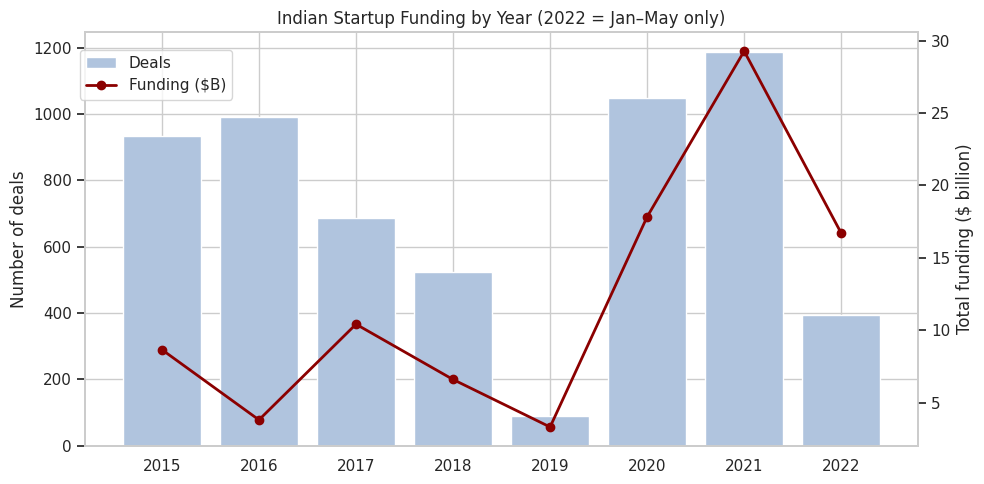

In [ ]:
yearly = df.groupby('Year').agg(deals=('Startup', 'count'),
                                funding_bn=('Amount_USD', lambda x: x.sum() / 1e9)).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(yearly['Year'].astype(str), yearly['deals'], color='lightsteelblue', label='Deals')
ax1.set_ylabel('Number of deals')
ax2 = ax1.twinx()                               # second y-axis on the right
ax2.plot(yearly['Year'].astype(str), yearly['funding_bn'], color='darkred', marker='o', linewidth=2, label='Funding ($B)')
ax2.set_ylabel('Total funding ($ billion)')
ax2.grid(False)
plt.title('Indian Startup Funding by Year (2022 = Jan–May only)')
fig.legend(loc='upper left', bbox_to_anchor=(0.08, 0.9))
save('01_funding_by_year')

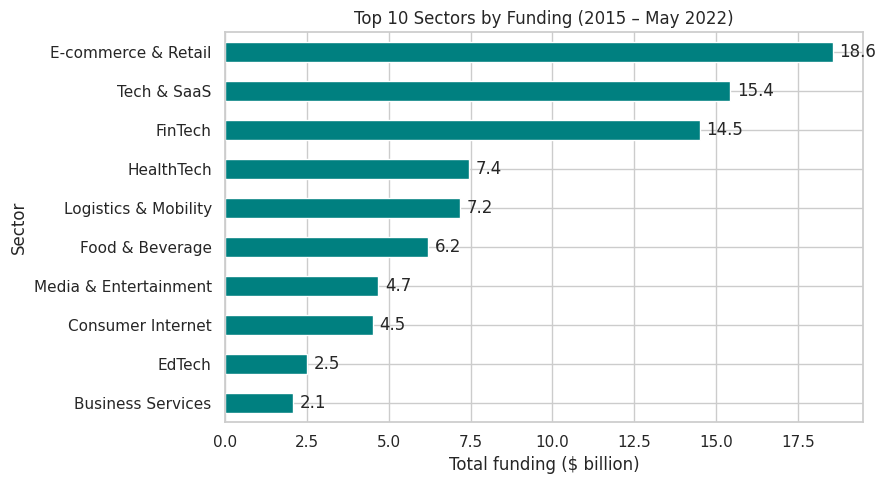

In [ ]:
sector = (df[~df['Sector'].isin(['Unknown', 'Other'])]
          .groupby('Sector')['Amount_USD'].sum().div(1e9)
          .sort_values().tail(10))

plt.figure(figsize=(9, 5))
sector.plot(kind='barh', color='teal')
plt.xlabel('Total funding ($ billion)')
plt.title('Top 10 Sectors by Funding (2015 – May 2022)')
for i, v in enumerate(sector):
    plt.text(v + 0.2, i, f'{v:.1f}', va='center')     # value labels
save('02_top_sectors')

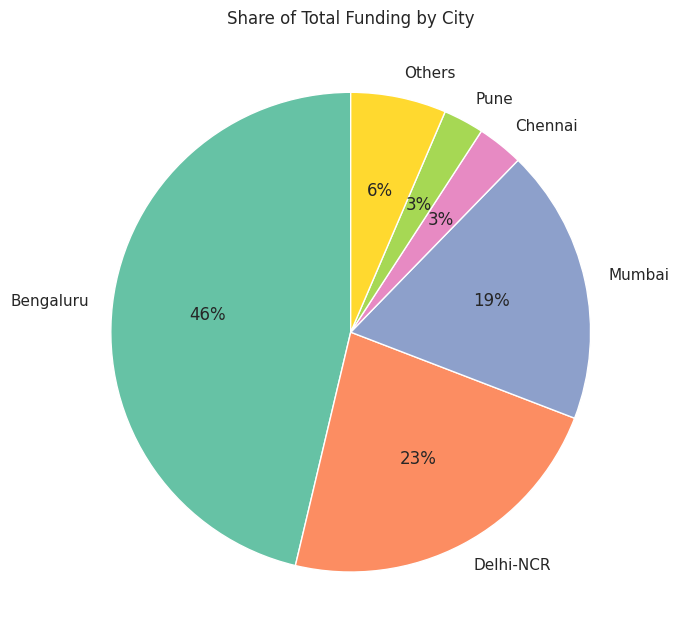

In [ ]:
city = df.copy()
city['City_Group'] = city['City_Std'].replace({'Delhi': 'Delhi-NCR', 'Gurugram': 'Delhi-NCR', 'Noida': 'Delhi-NCR'})
city = city[~city['City_Group'].isin(['Unknown', 'Outside India', 'Shanghai'])]
top = city.groupby('City_Group')['Amount_USD'].sum().sort_values(ascending=False)
top5 = pd.concat([top.head(5), pd.Series({'Others': top.iloc[5:].sum()})]) / 1e9

plt.figure(figsize=(7, 7))
plt.pie(top5, labels=top5.index, autopct='%1.0f%%', startangle=90,
        colors=sns.color_palette('Set2'), wedgeprops={'edgecolor': 'white'})
plt.title('Share of Total Funding by City')
save('03_city_share')

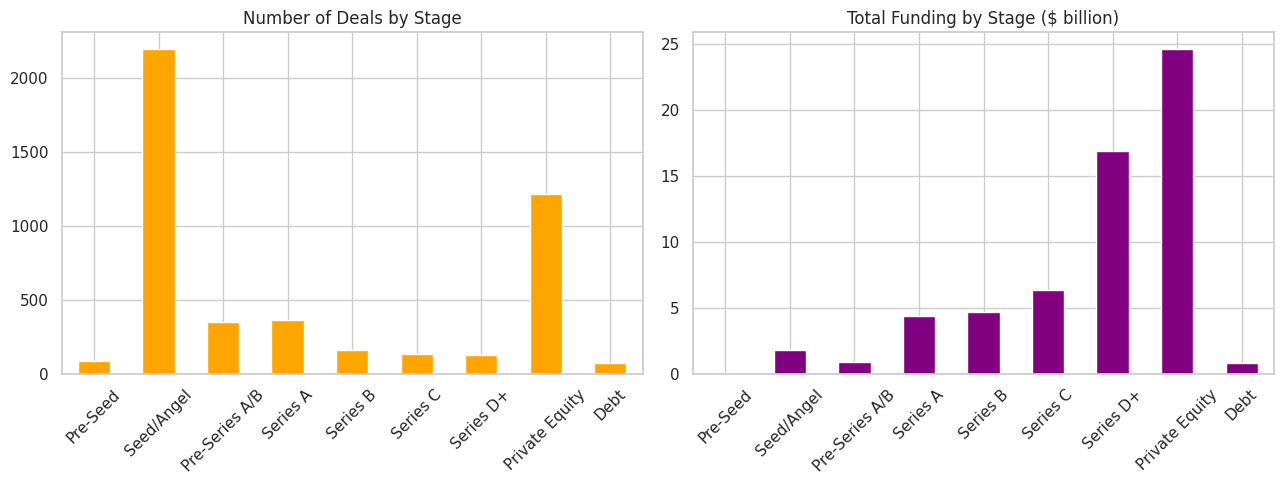

In [ ]:
stage_order = ['Pre-Seed', 'Seed/Angel', 'Pre-Series A/B', 'Series A', 'Series B',
               'Series C', 'Series D+', 'Private Equity', 'Debt']
st = (df[df['Stage_Std'].isin(stage_order)]
      .groupby('Stage_Std').agg(deals=('Startup', 'count'),
                                funding_bn=('Amount_USD', lambda x: x.sum() / 1e9))
      .reindex(stage_order))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
st['deals'].plot(kind='bar', ax=axes[0], color='orange')
axes[0].set_title('Number of Deals by Stage')
st['funding_bn'].plot(kind='bar', ax=axes[1], color='purple')
axes[1].set_title('Total Funding by Stage ($ billion)')
for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)
save('04_stage_deals_vs_funding')

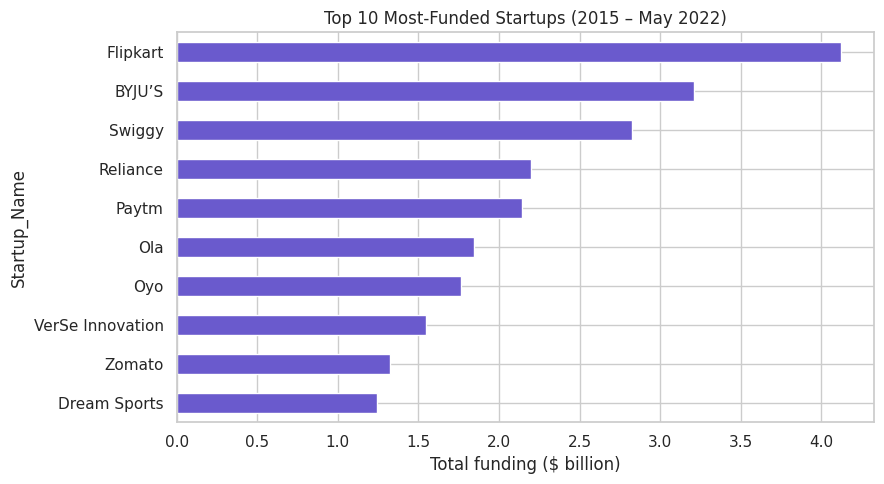

In [ ]:
df['Startup_Name'] = df['Startup'].str.strip().str.lower().str.replace("’", "'")
name_map = df.groupby('Startup_Name')['Startup'].first()      # keep a nice display name
top_st = df.groupby('Startup_Name')['Amount_USD'].sum().div(1e9).sort_values().tail(10)
top_st.index = top_st.index.map(name_map)

plt.figure(figsize=(9, 5))
top_st.plot(kind='barh', color='slateblue')
plt.xlabel('Total funding ($ billion)')
plt.title('Top 10 Most-Funded Startups (2015 – May 2022)')
save('05_top_startups')

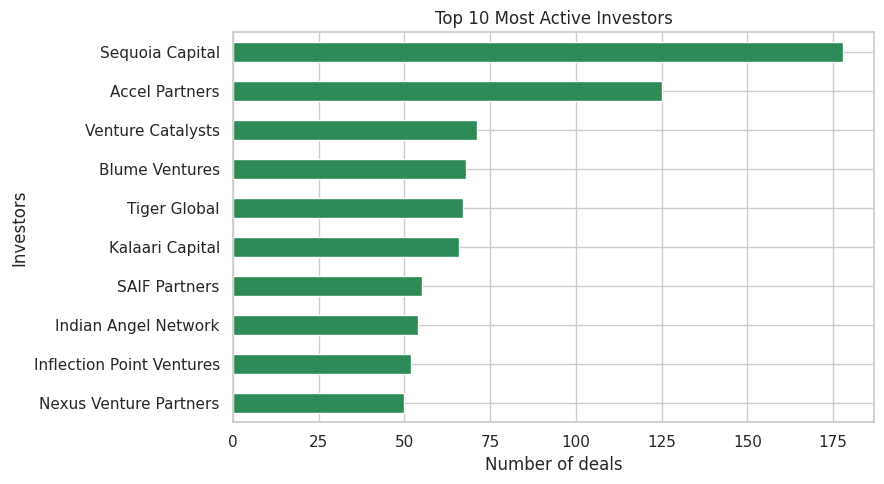

Investors
Sequoia Capital              178
Accel Partners               125
Venture Catalysts             71
Blume Ventures                68
Tiger Global                  67
Kalaari Capital               66
SAIF Partners                 55
Indian Angel Network          54
Inflection Point Ventures     52
Nexus Venture Partners        50
Name: count, dtype: int64


In [ ]:
inv = (df['Investors'].dropna()
       .str.replace(' and ', ',', regex=False)
       .str.split(',').explode().str.strip())
inv = inv.replace({'Sequoia Capital India': 'Sequoia Capital', 'Sequoia India': 'Sequoia Capital',
                   'Accel': 'Accel Partners', 'Accel India': 'Accel Partners', 'Accel Partners India': 'Accel Partners'})
inv = inv[(inv != '') & (~inv.str.contains('ndisclosed|investors|Angel investors|N/A', case=False))]
top_inv = inv.value_counts().head(10).sort_values()
plt.figure(figsize=(9, 5))
top_inv.plot(kind='barh', color='seagreen')
plt.xlabel('Number of deals')
plt.title('Top 10 Most Active Investors')
save('06_top_investors')
print(top_inv.sort_values(ascending=False))

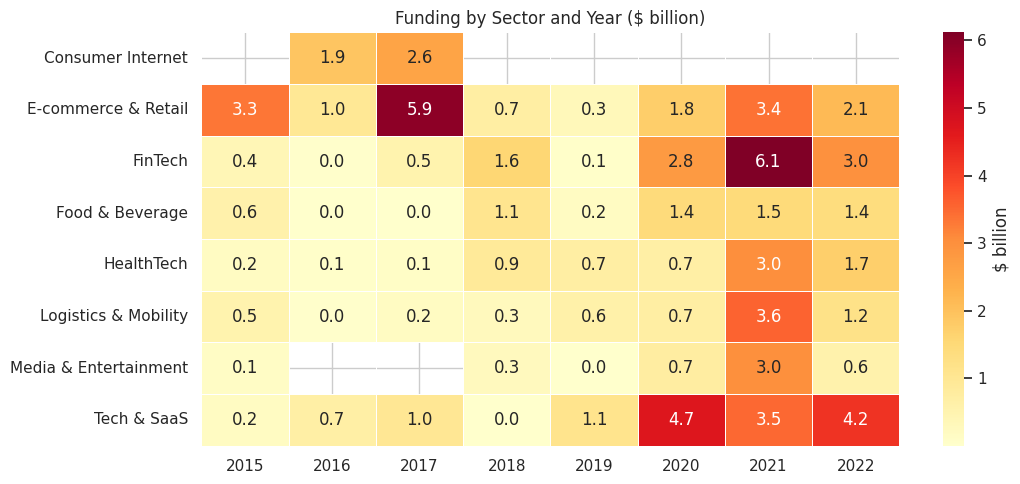

In [ ]:
top_sectors = sector.index[::-1][:8]
heat = (df[df['Sector'].isin(top_sectors)]
        .pivot_table(index='Sector', columns='Year', values='Amount_USD', aggfunc='sum') / 1e9)

plt.figure(figsize=(11, 5))
sns.heatmap(heat, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=0.5,
            cbar_kws={'label': '$ billion'})
plt.title('Funding by Sector and Year ($ billion)')
plt.xlabel('')
plt.ylabel('')
save('07_sector_year_heatmap')

In [ ]:
!zip -r charts.zip charts
from google.colab import files
files.download('charts.zip')

updating: charts/ (stored 0%)
updating: charts/07_sector_year_heatmap.png (deflated 9%)
updating: charts/04_stage_deals_vs_funding.png (deflated 20%)
updating: charts/06_top_investors.png (deflated 19%)
updating: charts/05_top_startups.png (deflated 20%)
updating: charts/01_funding_by_year.png (deflated 10%)
updating: charts/02_top_sectors.png (deflated 17%)
updating: charts/03_city_share.png (deflated 7%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>